In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline as make_sklearn_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, f1_score
)
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import make_pipeline as make_imb_pipeline

RANDOM_STATE = 42
csv_file = 'iris.csv'
df = pd.read_csv(csv_file)
df.head()


,id,sepal_length,sepal_width,petal_length,petal_width,species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [41]:
# Create an imbalanced example
class_counts = {
    'Iris-setosa': 50,
    'Iris-versicolor': 20,
    'Iris-virginica': 10,
}

# Sample reproducibly within each class to create the desired class distribution.
imbalanced_df = pd.concat([
    group.sample(n=class_counts[label], random_state=RANDOM_STATE)
    for label, group in df.groupby('species')
], ignore_index=True).sample(frac=1, random_state=RANDOM_STATE)

print('Class counts:')
print(imbalanced_df['species'].value_counts())
print('Class proportions:')
print(imbalanced_df['species'].value_counts(normalize=True).round(3))


Class counts:
species
Iris-setosa        50
Iris-versicolor    20
Iris-virginica     10
Name: count, dtype: int64
Class proportions:
species
Iris-setosa        0.625
Iris-versicolor    0.250
Iris-virginica     0.125
Name: proportion, dtype: float64


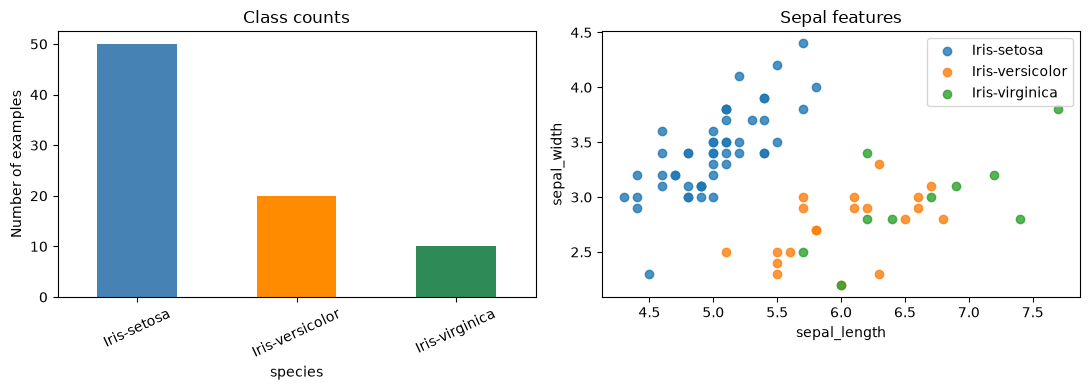

In [28]:
# Visualise the class imbalance and feature distributions.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
imbalanced_df['species'].value_counts().plot.bar(ax=axes[0], color=['steelblue', 'darkorange', 'seagreen'])
axes[0].set_title('Class counts')
axes[0].set_ylabel('Number of examples')
axes[0].tick_params(axis='x', rotation=25)

for label, group in imbalanced_df.groupby('species'):
    axes[1].scatter(group['sepal_length'], group['sepal_width'], label=label, alpha=0.8)
axes[1].set_xlabel('sepal_length')
axes[1].set_ylabel('sepal_width')
axes[1].set_title('Sepal features')
axes[1].legend()
plt.tight_layout()
plt.show()

In [42]:
#split the data
features = ['sepal_length', 'sepal_width']
# To use all four measurements, uncomment the next line.
# features = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

X = imbalanced_df[features]
y = imbalanced_df['species']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)

print('Training class counts:')
print(y_train.value_counts())
print('\nTest class counts:')
print(y_test.value_counts())

Training class counts:
species
Iris-setosa        35
Iris-versicolor    14
Iris-virginica      7
Name: count, dtype: int64

Test class counts:
species
Iris-setosa        15
Iris-versicolor     6
Iris-virginica      3
Name: count, dtype: int64


In [43]:
#Compare ordinary k-NN and random oversampling
k_values = [k for k in range(1, 30, 2) if k < len(X_train)]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'f1_macro': 'f1_macro',
    'balanced_accuracy': 'balanced_accuracy',
    'accuracy': 'accuracy',
}

rows = []
for strategy in ['ordinary', 'oversampled']:
    for k in k_values:
        if strategy == 'ordinary':
            model = make_sklearn_pipeline(
                StandardScaler(),
                KNeighborsClassifier(n_neighbors=k)
            )
        else:
            model = make_imb_pipeline(
                StandardScaler(),
                RandomOverSampler(random_state=RANDOM_STATE),
                KNeighborsClassifier(n_neighbors=k)
            )

        scores = cross_validate(
            model, X_train, y_train, cv=cv, scoring=scoring,
            return_train_score=False
        )
        rows.append({
            'strategy': strategy,
            'k': k,
            'f1_macro': scores['test_f1_macro'].mean(),
            'balanced_accuracy': scores['test_balanced_accuracy'].mean(),
            'accuracy': scores['test_accuracy'].mean(),
        })

cv_results = pd.DataFrame(rows)
cv_results.sort_values(['strategy', 'k']).head()


,strategy,k,f1_macro,balanced_accuracy,accuracy
0,ordinary,1,0.583126,0.623810,0.821212
1,ordinary,3,0.574237,0.634921,0.839394
2,ordinary,5,0.570586,0.634921,0.840909
3,ordinary,7,0.586508,0.644444,0.857576
4,ordinary,9,0.565714,0.622222,0.840909


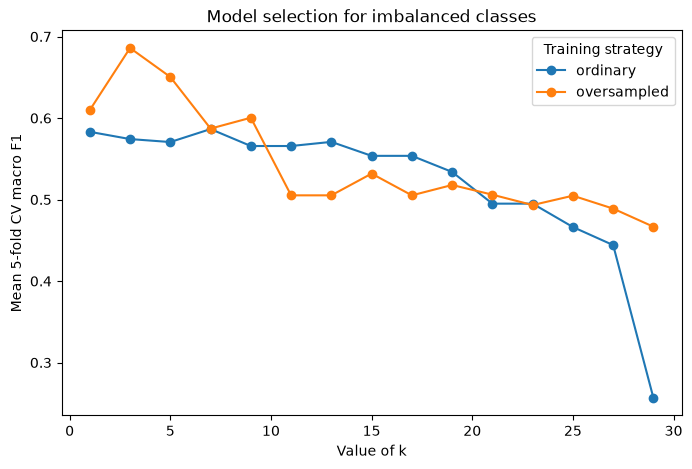

      strategy  k  f1_macro  balanced_accuracy  accuracy
0     ordinary  7  0.586508           0.644444  0.857576
1  oversampled  3  0.685983           0.712698  0.857576


In [44]:
#visulalisation 
fig, ax = plt.subplots(figsize=(8, 5))
for strategy, group in cv_results.groupby('strategy'):
    ax.plot(group['k'], group['f1_macro'], marker='o', label=strategy)
ax.set_xlabel('Value of k')
ax.set_ylabel('Mean 5-fold CV macro F1')
ax.set_title('Model selection for imbalanced classes')
ax.legend(title='Training strategy')
plt.show()

best_rows = (
    cv_results.sort_values('f1_macro', ascending=False)
              .groupby('strategy', as_index=False)
              .first()
)
print(best_rows)


=== ordinary (k=7) ===
Accuracy: 0.875
Balanced accuracy: 0.667
Macro F1: 0.6
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       0.67      1.00      0.80         6
 Iris-virginica       0.00      0.00      0.00         3

       accuracy                           0.88        24
      macro avg       0.56      0.67      0.60        24
   weighted avg       0.79      0.88      0.83        24



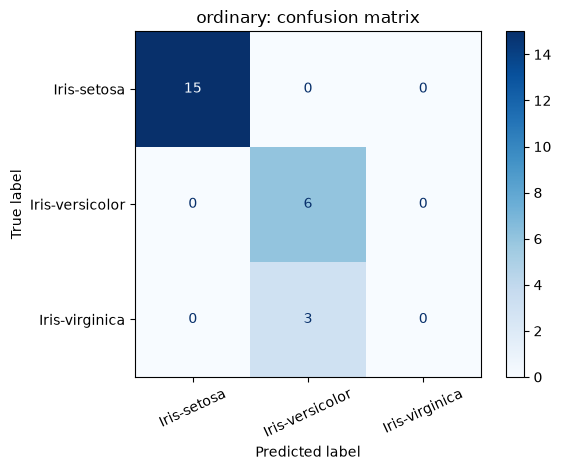


=== oversampled (k=3) ===
Accuracy: 0.833
Balanced accuracy: 0.722
Macro F1: 0.7
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       0.75      0.50      0.60         6
 Iris-virginica       0.40      0.67      0.50         3

       accuracy                           0.83        24
      macro avg       0.72      0.72      0.70        24
   weighted avg       0.86      0.83      0.84        24



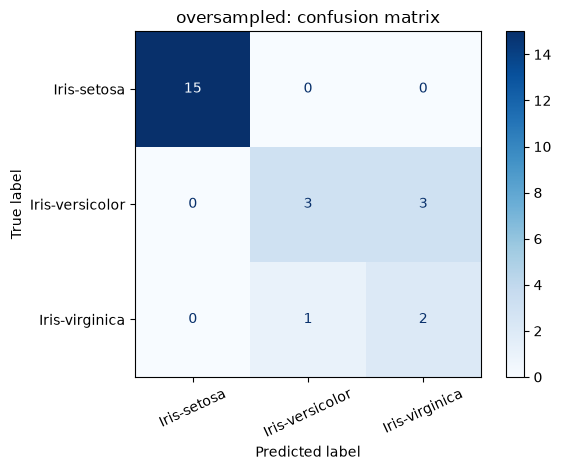

In [39]:
fitted_models = {}
for _, row in best_rows.iterrows():
    strategy = row['strategy']
    best_k = int(row['k'])
    if strategy == 'ordinary':
        model = make_sklearn_pipeline(
            StandardScaler(),
            KNeighborsClassifier(n_neighbors=best_k)
        )
    else:
        model = make_imb_pipeline(
            StandardScaler(),
            RandomOverSampler(random_state=RANDOM_STATE),
            KNeighborsClassifier(n_neighbors=best_k)
        )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    fitted_models[strategy] = model

    print(f'\n=== {strategy} (k={best_k}) ===')
    print('Accuracy:', round(accuracy_score(y_test, predictions), 3))
    print('Balanced accuracy:', round(balanced_accuracy_score(y_test, predictions), 3))
    print('Macro F1:', round(f1_score(y_test, predictions, average='macro', zero_division=0), 3))
    print(classification_report(y_test, predictions, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, labels=list(class_counts.keys()),
        xticks_rotation=25, cmap='Blues'
    )
    plt.title(f'{strategy}: confusion matrix')
    plt.tight_layout()
    plt.show()